In [ ]:
!pip install opencv-python-headless pyyaml pandas matplotlib seaborn pillow

In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))

dataset_path = "/content/traffic_dataset"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset uploaded and extracted successfully!")
print("Dataset location:", dataset_path)

Saving traffic_dataset_final (1).zip to traffic_dataset_final (1).zip
Dataset uploaded and extracted successfully!
Dataset location: /content/traffic_dataset


In [ ]:
import glob
import yaml

# Find image folders
image_folders = glob.glob(
    dataset_path + "/**/images",
    recursive=True
)

# Find label folders
label_folders = glob.glob(
    dataset_path + "/**/labels",
    recursive=True
)

print("Image folders found:", image_folders)
print("Label folders found:", label_folders)

# Default class names (change these to match your dataset)
class_names = [
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "truck",
    "traffic_light"
]

# Look for data.yaml
yaml_files = glob.glob(
    dataset_path + "/**/data.yaml",
    recursive=True
)

if yaml_files:
    with open(yaml_files[0], "r") as f:
        config = yaml.safe_load(f)

    names = config.get("names")

    if isinstance(names, dict):
        class_names = [
            names[i] for i in sorted(names.keys())
        ]
    elif isinstance(names, list):
        class_names = names

print("Dataset classes:", class_names)

Image folders found: ['/content/traffic_dataset/traffic_dataset/images']
Label folders found: ['/content/traffic_dataset/traffic_dataset/labels']
Dataset classes: ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic_light']


In [ ]:
import cv2
import pandas as pd
import numpy as np
from pathlib import Path

image_extensions = [
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
]

# Collect image paths
image_paths = []

for folder in image_folders:
    for extension in image_extensions:
        image_paths.extend(
            glob.glob(
                folder + "/**/*" + extension,
                recursive=True
            )
        )

image_paths = sorted(set(image_paths))

# Match image folders with corresponding label folders
folder_pairs = []

for image_folder in image_folders:
    relative_part = Path(image_folder).relative_to(dataset_path)
    label_folder = Path(dataset_path) / relative_part.parent / "labels"

    if label_folder.exists():
        folder_pairs.append((Path(image_folder), label_folder))

print("Total images found:", len(image_paths))
print("Image-label folder pairs:", len(folder_pairs))

Total images found: 26
Image-label folder pairs: 1


In [ ]:
quality_results = []

for image_path in image_paths:

    image = cv2.imread(image_path)

    if image is None:
        quality_results.append({
            "image": os.path.basename(image_path),
            "width": 0,
            "height": 0,
            "blur_score": 0,
            "status": "Corrupted"
        })
        continue

    height, width = image.shape[:2]

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    blur_score = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    if width < 100 or height < 100:
        status = "Low Resolution"
    elif blur_score < 50:
        status = "Possibly Blurry"
    else:
        status = "Good Quality"

    quality_results.append({
        "image": os.path.basename(image_path),
        "width": width,
        "height": height,
        "blur_score": round(blur_score, 2),
        "status": status
    })

quality_df = pd.DataFrame(quality_results)

print("IMAGE QUALITY REPORT")
display(quality_df.head(10))

print("\nQuality Summary:")
print(quality_df["status"].value_counts())

IMAGE QUALITY REPORT


,image,width,height,blur_score,status
0,image001.jpg,600,400,840.75,Good Quality
1,image002.jpg,758,502,226.80,Good Quality
2,image003.jpg,1102,479,5114.32,Good Quality
3,image004.jpg,2048,1191,43.64,Possibly Blurry
4,image005.jpg,640,480,3080.30,Good Quality
5,image006.jpg,640,425,4327.19,Good Quality
6,image007.jpg,640,428,928.40,Good Quality
7,image008.jpg,640,426,2841.52,Good Quality
8,image009.jpg,640,480,3080.30,Good Quality
9,image010.jpg,640,480,1486.92,Good Quality



Quality Summary:
status
Good Quality       25
Possibly Blurry     1
Name: count, dtype: int64


In [ ]:
annotation_results = []
class_counts = {}

missing_labels = []
invalid_annotations = []

image_label_pairs = {}

for image_folder, label_folder in folder_pairs:

    for image_path in image_folder.rglob("*"):

        if image_path.suffix.lower() not in image_extensions:
            continue

        relative_path = image_path.relative_to(image_folder)

        label_path = (
            label_folder / relative_path.with_suffix(".txt")
        )

        image_label_pairs[str(image_path)] = label_path

for image_path, label_path in image_label_pairs.items():

    if not label_path.exists():

        missing_labels.append(image_path)

        annotation_results.append({
            "image": os.path.basename(image_path),
            "objects": 0,
            "validation": "Missing label"
        })

        continue

    object_count = 0
    valid = True

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line_number, line in enumerate(lines, start=1):

        if not line.strip():
            continue

        try:
            values = list(map(float, line.split()))

            if len(values) != 5:
                raise ValueError("Expected five values")

            class_id = int(values[0])
            x, y, w, h = values[1:]

            if values[0] != class_id:
                raise ValueError("Class ID must be an integer")

            if not (0 <= class_id < len(class_names)):
                raise ValueError("Invalid class ID")

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                raise ValueError("Invalid bounding box")

            if x - w / 2 < -1e-6 or x + w / 2 > 1 + 1e-6:
                raise ValueError("Bounding box exceeds image width")

            if y - h / 2 < -1e-6 or y + h / 2 > 1 + 1e-6:
                raise ValueError("Bounding box exceeds image height")

            class_counts[class_id] = (
                class_counts.get(class_id, 0) + 1
            )

            object_count += 1

        except Exception as error:

            valid = False

            invalid_annotations.append({
                "file": str(label_path),
                "line": line_number,
                "error": str(error)
            })

    annotation_results.append({
        "image": os.path.basename(image_path),
        "objects": object_count,
        "validation": "Valid" if valid else "Invalid"
    })

annotation_df = pd.DataFrame(annotation_results)

print("ANNOTATION VALIDATION REPORT")
display(annotation_df.head(10))

print("Missing label files:", len(missing_labels))
print("Invalid annotation lines:", len(invalid_annotations))
print("Total annotated objects:", sum(class_counts.values()))

ANNOTATION VALIDATION REPORT


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

class_distribution = {
    class_names[class_id]: count
    for class_id, count in class_counts.items()
}

plt.figure(figsize=(12, 6))

sns.barplot(
    x=list(class_distribution.keys()),
    y=list(class_distribution.values())
)

plt.title("Object Class Distribution")
plt.xlabel("Object Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
quality_counts = quality_df["status"].value_counts()

plt.figure(figsize=(8, 5))

plt.pie(
    quality_counts.values,
    labels=quality_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Image Quality Distribution")
plt.show()

Image: /content/traffic_dataset/traffic_dataset/images/image004.jpg


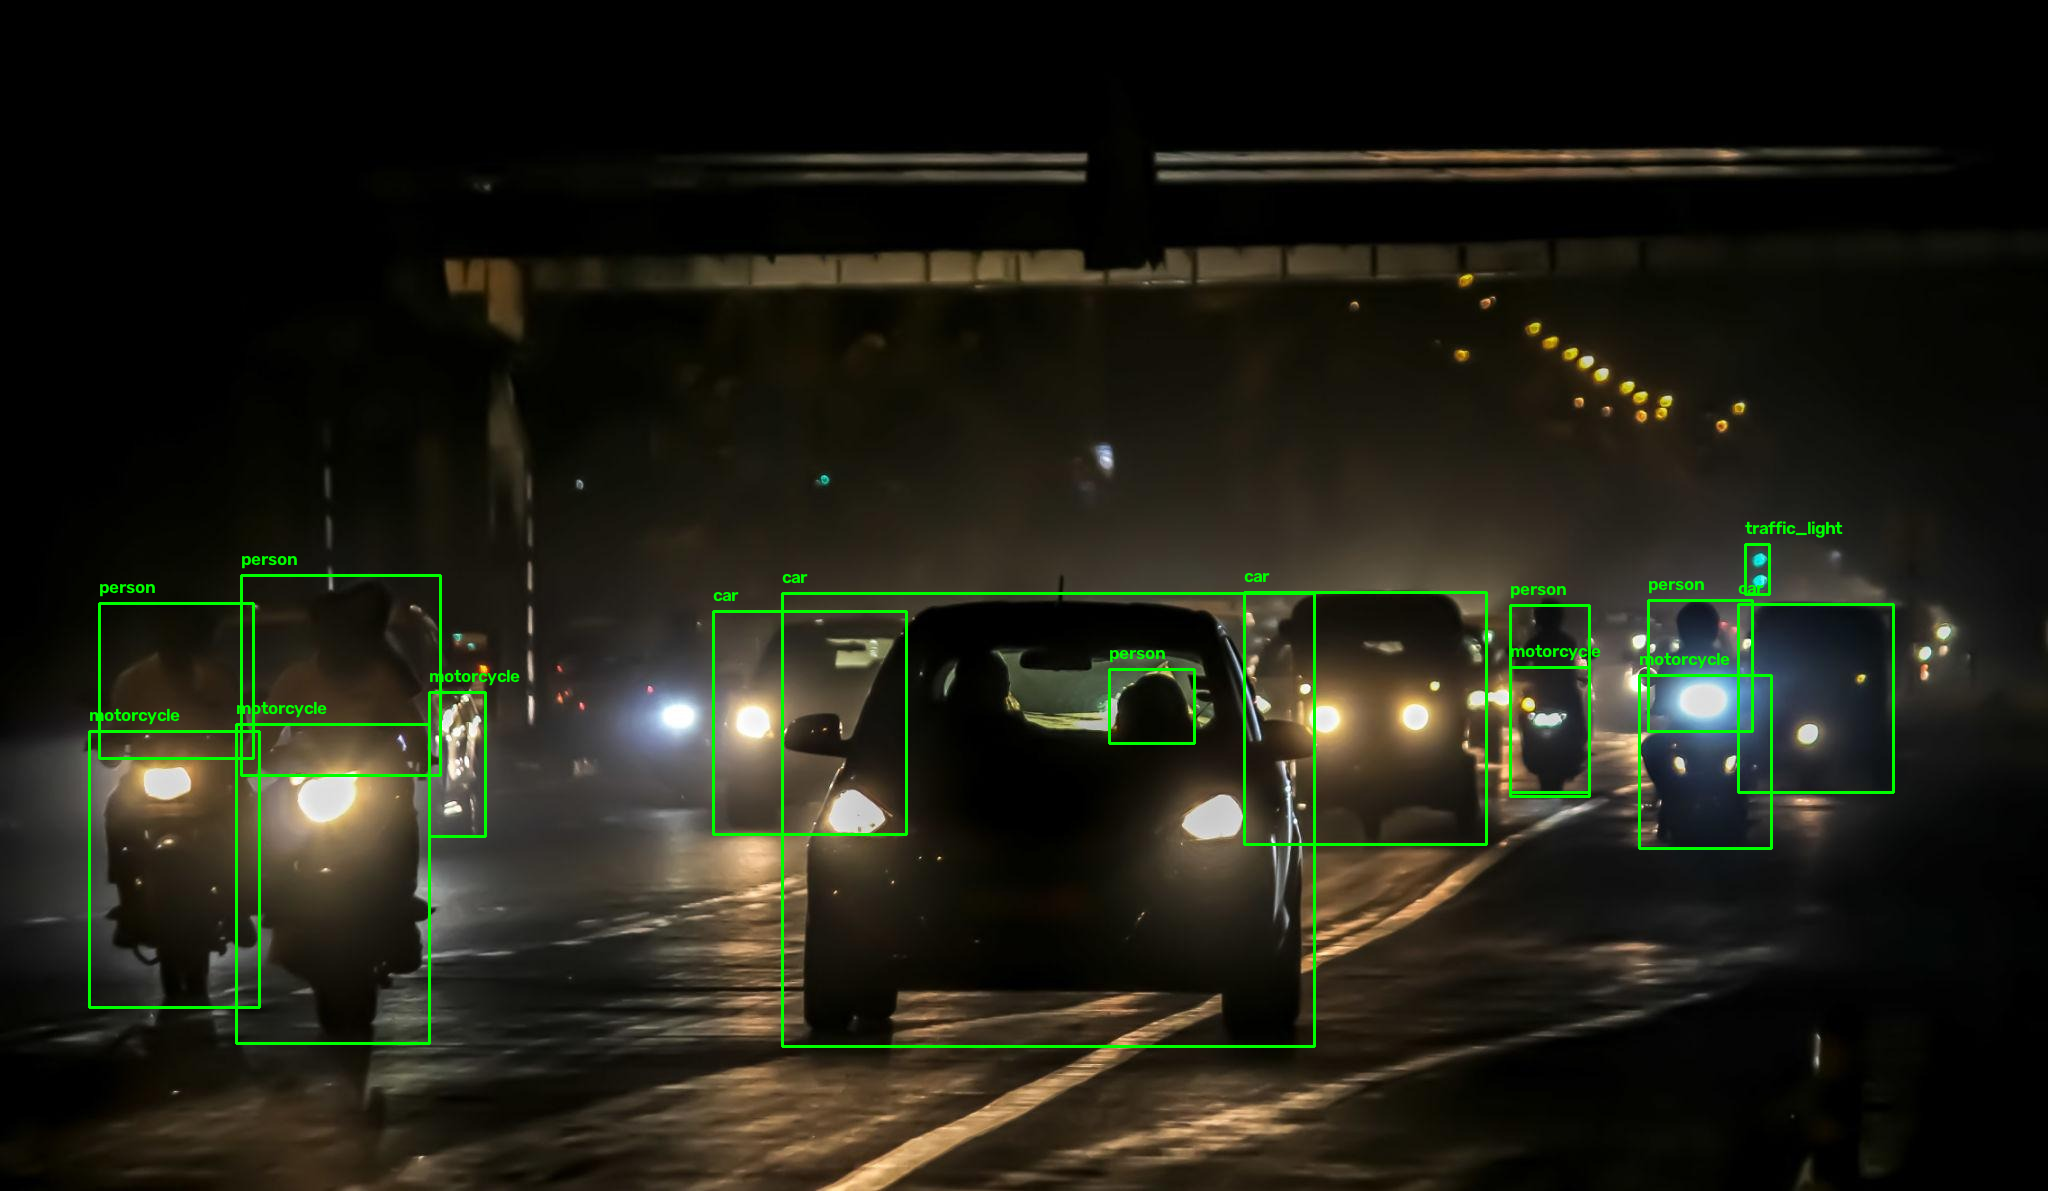

In [ ]:
import random
from google.colab.patches import cv2_imshow

# Select a random image that has a label file
available_images = [
    path for path in image_label_pairs
    if image_label_pairs[path].exists()
]

if available_images:

    selected_image = random.choice(available_images)

    image = cv2.imread(selected_image)

    label_path = image_label_pairs[selected_image]

    height, width = image.shape[:2]

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:

        values = list(map(float, line.split()))

        if len(values) != 5:
            continue

        class_id = int(values[0])
        x, y, w, h = values[1:]

        x1 = int((x - w / 2) * width)
        y1 = int((y - h / 2) * height)

        x2 = int((x + w / 2) * width)
        y2 = int((y + h / 2) * height)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            class_names[class_id],
            (x1, max(20, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    print("Image:", selected_image)
    cv2_imshow(image)

else:
    print("No image-label pairs found.")

In [ ]:
print("=" * 50)
print("       VISIONPORT DATASET AUDIT REPORT")
print("=" * 50)

print("\n1. DATASET INFORMATION")
print("Total Images:", len(image_paths))

print("\n2. IMAGE QUALITY")
print(quality_df["status"].value_counts().to_dict())

print("\n3. CLASS DISTRIBUTION")

for class_id, count in sorted(class_counts.items()):
    print(f"{class_names[class_id]}: {count}")

print("\n4. ANNOTATION VALIDATION")
print("Missing Labels:", len(missing_labels))
print("Invalid Annotation Lines:", len(invalid_annotations))
print("Total Objects:", sum(class_counts.values()))

print("\n5. FINAL STATUS")

if len(missing_labels) == 0 and len(invalid_annotations) == 0:
    print("All checked annotations passed validation.")
else:
    print("Dataset needs annotation corrections.")

print("=" * 50)

       VISIONPORT DATASET AUDIT REPORT

1. DATASET INFORMATION
Total Images: 26

2. IMAGE QUALITY
{'Good Quality': 25, 'Possibly Blurry': 1}

3. CLASS DISTRIBUTION
person: 112
bicycle: 8
car: 177
motorcycle: 15
bus: 16
truck: 30
traffic_light: 25

4. ANNOTATION VALIDATION
Missing Labels: 0
Invalid Annotation Lines: 0
Total Objects: 383

5. FINAL STATUS
All checked annotations passed validation.
